# A/B-тест: визуализация и проверка статистики

Тот же сценарий, что и в `ab_test_analysis.py`: тест нового алгоритма рекомендаций.
Здесь — генерация данных (`numpy.random.default_rng(seed=42)`, те же параметры, что
в скрипте: 5 000 + 5 000, pA=4.2%, pB=5.2%), z-тест для пропорций и графики.

> Данные синтетические (реальные A/B-тесты компаний не публикуются); про ограничения
> см. README. Сам метод и выводы — те же, что применяются к реальным тестам.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
from scipy import stats

RNG = np.random.default_rng(seed=42)
N_A, N_B = 5_000, 5_000
P_A, P_B = 0.042, 0.052
a = RNG.binomial(1, P_A, size=N_A)
b = RNG.binomial(1, P_B, size=N_B)

nA, nB = a.sum(), b.sum()
xA, xB = nA / N_A, nB / N_B
print(f"Конверсия A: {nA}/{N_A} = {xA:.4f}")
print(f"Конверсия B: {nB}/{N_B} = {xB:.4f}")

Конверсия A: 210/5000 = 0.0420
Конверсия B: 271/5000 = 0.0542


## Z-тест для пропорций (основной метод)

Pooled standard error при H0: pA = pB. Welch t-test — только как перекрёстная проверка.

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
p_pool = (nA + nB) / (N_A + N_B)
se = np.sqrt(p_pool * (1 - p_pool) * (1/N_A + 1/N_B))
z = (xB - xA) / se
p_z = 2 * stats.norm.sf(abs(z))

# 95% CI для разницы (unpooled SE) и Cohen's h
se_diff = np.sqrt(xA*(1-xA)/N_A + xB*(1-xB)/N_B)
ci_lo, ci_hi = (xB - xA) - 1.96*se_diff, (xB - xA) + 1.96*se_diff
h = 2*np.arcsin(np.sqrt(xB)) - 2*np.arcsin(np.sqrt(xA))

print(f"z = {z:.3f}, p (two-sided) = {p_z:.4f}")
print(f"Абсолютный прирост: {(xB-xA)*100:+.2f} п.п.,  относительный: {(xB/xA-1)*100:+.1f}%")
print(f"95% CI разницы: [{ci_lo*100:.2f}%, {ci_hi*100:.2f}%]")
print(f"Cohen's h = {h:.3f} (малый эффект)")
print(f"Welch t-test p = {stats.ttest_ind(b, a, equal_var=False).pvalue:.4f} (cross-check)")

z = 2.851, p (two-sided) = 0.0044
Абсолютный прирост: +1.22 п.п.,  относительный: +29.0%
95% CI разницы: [0.38%, 2.06%]
Cohen's h = 0.057 (малый эффект)
Welch t-test p = 0.0044 (cross-check)


## График 1: конверсии с 95% доверительными интервалами

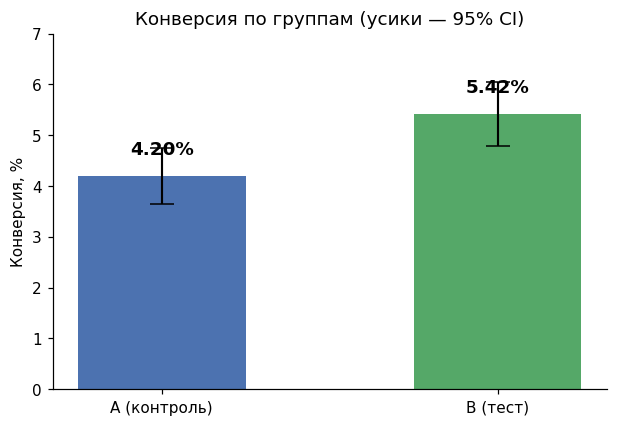

In [3]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ci_a = 1.96*np.sqrt(xA*(1-xA)/N_A)
ci_b = 1.96*np.sqrt(xB*(1-xB)/N_B)
bars = ax.bar(["A (контроль)", "B (тест)"], [xA*100, xB*100],
              yerr=[ci_a*100, ci_b*100], capsize=8,
              color=["#4C72B0", "#55A868"], width=0.5, error_kw={"lw": 1.4})
for b_, v, n in zip(bars, [xA, xB], [nA, nB]):
    ax.text(b_.get_x() + b_.get_width()/2, v*100 + 0.42, f"{v:.2%}",
            ha="center", fontsize=12, fontweight="bold")
ax.set_title("Конверсия по группам (усики — 95% CI)", fontsize=12)
ax.set_ylabel("Конверсия, %")
ax.set_ylim(0, 7)
plt.show()

## График 2: нулевое распределение разницы и наблюдаемый эффект

При H0 разница конверсий распределена примерно нормально вокруг 0 с SE по pooled формуле.
Наблюдаемая разница попадает в зону отвержения — эффект статистически значим.

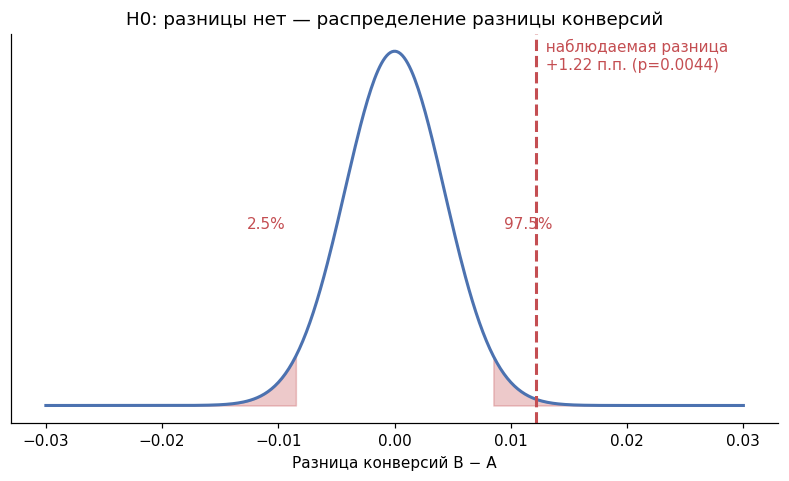

In [4]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
fig, ax = plt.subplots(figsize=(9, 4.6))
xs = np.linspace(-0.03, 0.03, 400)
pdf = stats.norm.pdf(xs, 0, se)
ax.plot(xs, pdf, color="#4C72B0", lw=2)
ax.fill_between(xs, pdf, where=xs < stats.norm.ppf(0.025)*se, color="#C44E52", alpha=0.3)
ax.fill_between(xs, pdf, where=xs > stats.norm.ppf(0.975)*se, color="#C44E52", alpha=0.3)
ax.axvline(xB - xA, color="#C44E52", lw=2, ls="--")
ax.text(xB - xA, pdf.max()*0.95, f"  наблюдаемая разница\n  {(xB-xA)*100:+.2f} п.п. (p={p_z:.4f})",
        color="#C44E52", fontsize=10)
ax.text(stats.norm.ppf(0.025)*se - 0.001, pdf.max()*0.5, "2.5%", color="#C44E52", ha="right")
ax.text(stats.norm.ppf(0.975)*se + 0.001, pdf.max()*0.5, "97.5%", color="#C44E52")
ax.set_title("H0: разницы нет — распределение разницы конверсий", fontsize=12)
ax.set_xlabel("Разница конверсий B − A")
ax.set_yticks([])
plt.show()

## Вывод

- Разница **+1.22 п.п.** статистически значима (p ≈ 0.004 < 0.05): вариант B действительно лучше.
- Но effect size мал (Cohen's h ≈ 0.057): при больших группах значимость достигается и на малых эффектах. Решение о раскатке — за **практической** значимостью: окупит ли прирост стоимость фичи.
- SRM-проверка: соотношение групп 5000/5000 = 50/50, как заявлено — тест можно доверять.

**Ограничение:** данные синтетические — они демонстрируют метод, а не реальный продукт.
Как применить к реальным данным: подайте CSV с колонками `group`, `converted` в
`ab_test_analysis.py` (блок генерации заменяется на `pd.read_csv`).